# 04 — Do ratings differ by genre, and how should that shape the filters?

**Question.** Step 4 removes movies that are not worth recommending. One rule for every movie (low average rating, few ratings, old) is simple, but it is only fair if genres rate about the same. If Horror simply rates lower than Documentary, one rating cutoff would remove decent Horror movies just for being Horror.

**What this notebook does**
1. Check whether average ratings are normally distributed.
2. Count movies per genre and choose the genres to analyse.
3. Compare rating distributions across genres. They differ.
4. Build a rating test per genre.
5. Build a rating-count test per genre.
6. Add an age test so recent movies are not rejected for having few ratings.
7. Combine the three tests into one `approve` flag, check it, clean the table and save it.

**Input:** `data/processed/movies_full.parquet`
**Output:** `data/processed/approved_movies.parquet` (written by the last code cell), tables in `artifacts/`, figures in `docs/findings/figures/`.

## 1. Config and load
Load the combined table and keep the 50,046 movies that have at least one rating. IMDb-filled genres use "," and MovieLens genres use "|", so the code converts "," to "|" once here. Every genre split below depends on it.

In [69]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Paths (assumes this notebook runs one level below the project root, e.g. notebooks/)
PROCESSED_DIR = Path("..") / "data" / "processed"
ARTIFACTS_DIR = Path("..") / "artifacts"
FIGURES_DIR = Path("..") / "docs" / "findings" / "figures"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

movies = pd.read_parquet(PROCESSED_DIR / "movies_full.parquet")
# IMDb-filled genres use "," and MovieLens uses "|"; use "|" everywhere so every split below works
movies["genres"] = movies["genres"].str.replace(",", "|", regex=False)
rated = movies[movies["rating_count"].notna()].copy()
print(f"{len(rated):,} rated movies (population for this analysis)")


50,046 rated movies (population for this analysis)


## 2. Are average ratings normally distributed?
Bands like μ ± σ only make sense if the data is roughly bell-shaped, so check that first. This uses movies with at least 10 ratings (21,960 movies), because an average from 1 to 9 ratings is too noisy. The next cell is a quick look at the table, the one after fits a normal curve to the ratings.

In [70]:
rated.head()

,movieId,tconst,tmdbId,title,genres,year,has_ratings,is_imdb_matched,rating_count,mean_rating,titleType,runtimeMinutes,ml_genres,imdb_genres,ml_year,imdb_year
0,1,tt0114709,862.0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,True,True,57309.0,3.893708,movie,81,Adventure|Animation|Children|Comedy|Fantasy,"Adventure,Animation,Comedy",1995.0,1995.0
1,2,tt0113497,8844.0,Jumanji (1995),Adventure|Children|Fantasy,1995.0,True,True,24228.0,3.251527,movie,104,Adventure|Children|Fantasy,"Adventure,Comedy,Family",1995.0,1995.0
2,3,tt0113228,15602.0,Grumpier Old Men (1995),Comedy|Romance,1995.0,True,True,11804.0,3.142028,movie,101,Comedy|Romance,"Comedy,Romance",1995.0,1995.0
3,4,tt0114885,31357.0,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,True,True,2523.0,2.853547,movie,124,Comedy|Drama|Romance,"Comedy,Drama,Romance",1995.0,1995.0
4,5,tt0113041,11862.0,Father of the Bride Part II (1995),Comedy,1995.0,True,True,11714.0,3.058434,movie,106,Comedy,"Comedy,Family,Romance",1995.0,1995.0


21,960 movies with at least 10 ratings


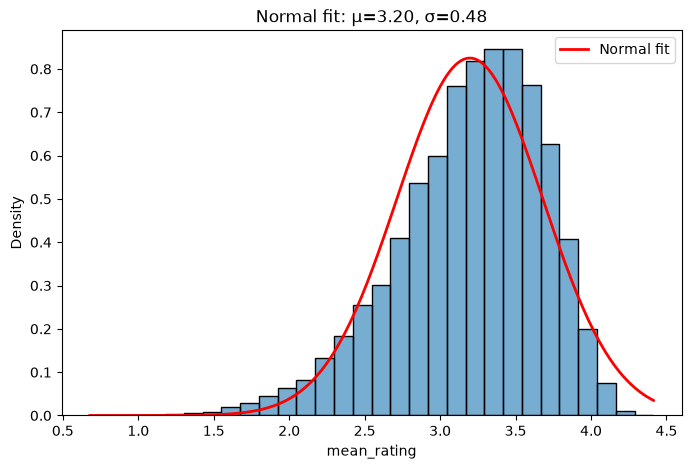

In [71]:
COL = "mean_rating"     # average rating per movie
MIN_VOTES = 10     # ignore movies with fewer ratings (their averages are too noisy)

if COL not in rated.columns:
    raise KeyError(f"'{COL}' not found. Available columns: {rated.columns.tolist()}")

data = rated.loc[rated["rating_count"] >= MIN_VOTES, COL].dropna()
print(f"{len(data):,} movies with at least {MIN_VOTES} ratings")

mu, sigma = stats.norm.fit(data)

plt.figure(figsize=(8, 5))
sns.histplot(data, bins=30, stat="density", alpha=0.6)
x = np.linspace(data.min(), data.max(), 200)
sns.lineplot(x=x, y=stats.norm.pdf(x, mu, sigma), color="red", lw=2, label="Normal fit")
plt.title(f"Normal fit: μ={mu:.2f}, σ={sigma:.2f}")
plt.xlabel(COL)
plt.ylabel("Density")

plt.savefig(FIGURES_DIR / "rating_normal_fit.png", dpi=150, bbox_inches="tight")
plt.show()

Numbers behind the picture: skewness, mean vs median, a Q-Q plot (points on the line would mean normal) and percentiles.

Skewness: -0.70
Mean: 3.20, Median: 3.26


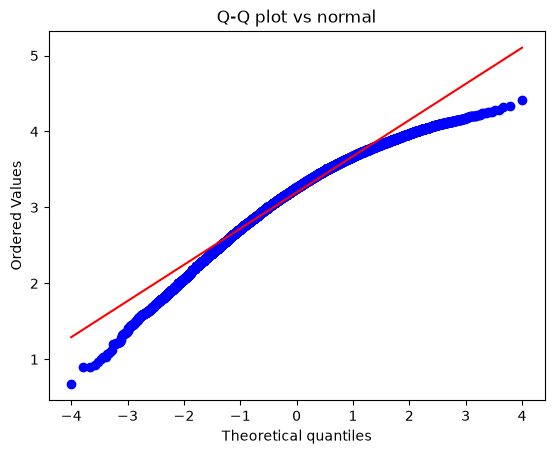

In [72]:
print(f"Skewness: {stats.skew(data):.2f}")   # negative = left-skewed
print(f"Mean: {data.mean():.2f}, Median: {data.median():.2f}")

stats.probplot(data, dist="norm", plot=plt)
plt.title("Q-Q plot vs normal")
plt.show()

In [73]:
print(data.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

0.01    1.829713
0.05    2.305543
0.25    2.901804
0.50    3.255814
0.75    3.552632
0.95    3.870372
0.99    4.045597
Name: mean_rating, dtype: float64


**Result.** Not normal. Skewness is −0.70, the mean (3.20) sits below the median (3.26), and the tail is longer on the low side (1st percentile 1.83, 99th percentile 4.05). A normal curve is only an approximation here. Every μ ± σ bound below is used with that in mind, and section 4 checks how close the approximation is per genre.

## 3. Which genres are there?
A movie can have several genres, so it is split into one row per (movie, genre). Genre counts therefore add up to more than the number of movies. `IMAX` is a screen format, not a genre, so it is excluded. A genre needs at least `MIN_MOVIES = 100` movies to be analysed on its own.

23 genres

genre
Drama          10932
Comedy          7023
Thriller        4018
Romance         3429
Action          3178
Crime           2488
Horror          2452
Adventure       1976
Sci-Fi          1607
Documentary     1468
Mystery         1282
Fantasy         1205
Children         940
War              892
Animation        795
Musical          680
Western          445
Film-Noir        256
Biography         19
History           11
Family             7
Music              5
Sport              1
Name: count, dtype: int64


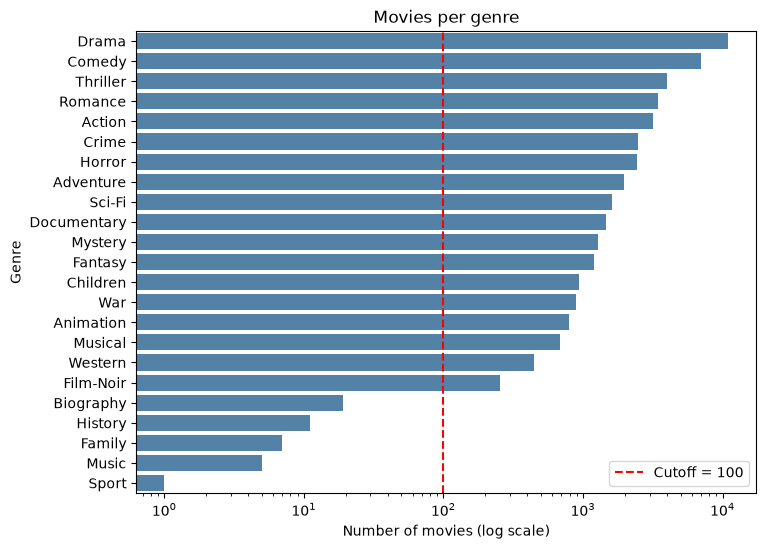


Keeping 18 genres
Dropped: {'Biography': 19, 'History': 11, 'Family': 7, 'Music': 5, 'Sport': 1}


In [74]:
MIN_VOTES = 10      # same vote filter as the normal-fit check above
MIN_MOVIES = 100    # minimum movies for a genre to be analysed
EXCLUDE = {"(no genres listed)", "IMAX"}   # IMAX is a format, not a genre

base = rated[rated["rating_count"] >= MIN_VOTES]

# One row per (movie, genre) pair
genre_df = base.assign(genre=base["genres"].str.split("|")).explode("genre")
genre_df = genre_df[~genre_df["genre"].isin(EXCLUDE)]

genre_counts = genre_df["genre"].value_counts()
print(f"{genre_counts.size} genres\n")
print(genre_counts)

# Movies per genre, with the cutoff line
plt.figure(figsize=(8, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index, color="steelblue")
plt.axvline(MIN_MOVIES, color="red", ls="--", label=f"Cutoff = {MIN_MOVIES}")
plt.xscale("log")
plt.xlabel("Number of movies (log scale)")
plt.ylabel("Genre")
plt.title("Movies per genre")
plt.legend()

plt.show()

keep = genre_counts[genre_counts >= MIN_MOVIES].index.tolist()
dropped = genre_counts[genre_counts < MIN_MOVIES]
print(f"\nKeeping {len(keep)} genres")
print("Dropped:", dropped.to_dict())

**Result.** 23 genres, 18 with at least 100 movies. Drama (10,932) and Comedy (7,023) are the largest. Biography, History, Family, Music and Sport have fewer than 20 movies each, too few to analyse. The next sections use the 10 largest genres and group everything else as `Other`, which keeps the number of groups manageable.

Next, the same counts as a bar chart (top 19 genres, the rest grouped as `Other`), saved to `docs/findings/figures/genre_counts.png`.

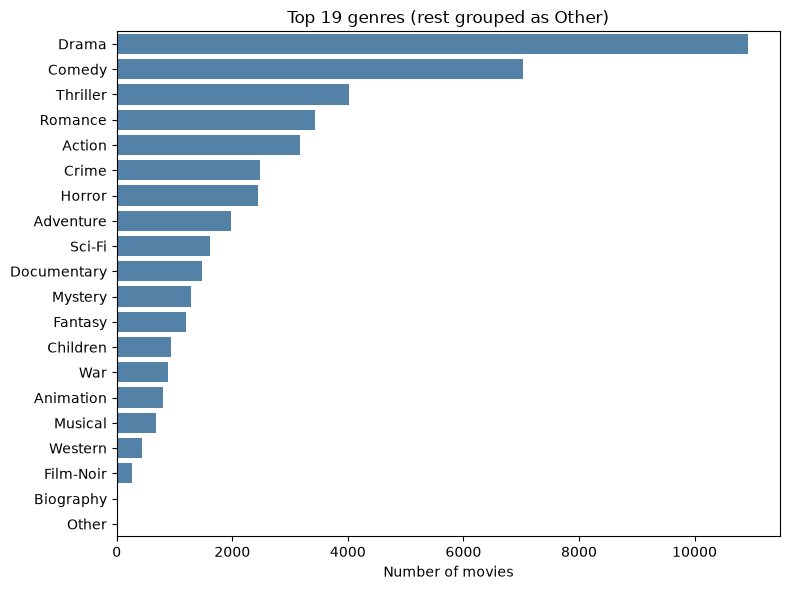

In [75]:
TOP_N = 19   # number of genres to show individually

genre_counts = (
    base["genres"].str.split("|").explode()
    .loc[lambda s: ~s.isin(EXCLUDE)]
    .value_counts()
)

plot_counts = genre_counts.head(TOP_N).copy()
plot_counts["Other"] = genre_counts.iloc[TOP_N:].sum()

plt.figure(figsize=(8, 6))
sns.barplot(x=plot_counts.values, y=plot_counts.index, color="steelblue")
plt.xlabel("Number of movies")
plt.ylabel("")
plt.title(f"Top {TOP_N} genres (rest grouped as Other)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "genre_counts.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Do ratings differ by genre?
Compare the rating distribution of the 10 largest genres plus `Other` (all remaining genres, each movie counted once there). Boxes are sorted by median and the table gives each genre's count and quartiles. Figure saved as `genre_boxplot.png`.

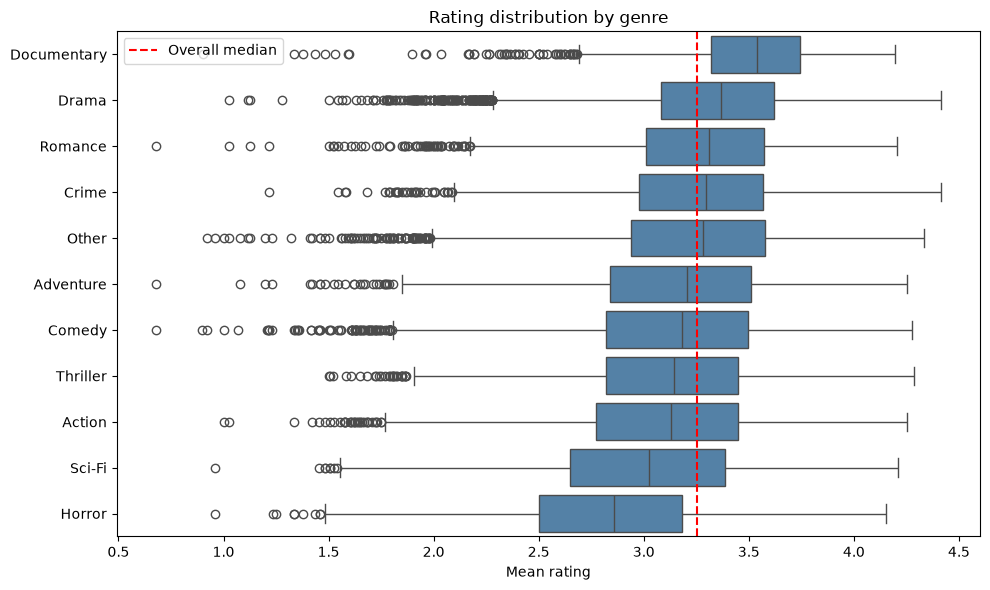

               count   25%   50%   75%
genre_group                           
Documentary   1468.0  3.32  3.54  3.74
Drama        10932.0  3.08  3.37  3.62
Romance       3429.0  3.01  3.31  3.57
Crime         2488.0  2.98  3.30  3.57
Other         5325.0  2.94  3.28  3.58
Adventure     1976.0  2.84  3.21  3.51
Comedy        7023.0  2.82  3.18  3.49
Thriller      4018.0  2.82  3.14  3.45
Action        3178.0  2.77  3.13  3.45
Sci-Fi        1607.0  2.65  3.02  3.39
Horror        2452.0  2.50  2.86  3.18


In [76]:
TOP_N = 10

genre_df = (
    base.assign(genre=base["genres"].str.split("|"))
        .explode("genre")
        .loc[lambda d: ~d["genre"].isin(EXCLUDE)]
)

top_genres = genre_df["genre"].value_counts().head(TOP_N).index

genre_df = genre_df.assign(
    genre_group=genre_df["genre"].where(genre_df["genre"].isin(top_genres), "Other")
).drop_duplicates(["movieId", "genre_group"])   # count each movie once in Other

# Sort boxes by median rating, highest first
order = (genre_df.groupby("genre_group")["mean_rating"]
         .median().sort_values(ascending=False).index)

plt.figure(figsize=(10, 6))
sns.boxplot(data=genre_df, x="mean_rating", y="genre_group", order=order, color="steelblue")
plt.axvline(base["mean_rating"].median(), color="red", ls="--", label="Overall median")
plt.xlabel("Mean rating")
plt.ylabel("")
plt.title("Rating distribution by genre")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "genre_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

print(genre_df.groupby("genre_group")["mean_rating"].describe()
      [["count", "25%", "50%", "75%"]].loc[order].round(2))

**Result.** Yes. Medians run from 3.54 (Documentary) down to 2.86 (Horror), a gap of 0.68 stars, and the order is consistent: Documentary, Drama, Romance and Crime at the top, Sci-Fi and Horror at the bottom. The boxes overlap, so genre does not decide a movie's rating, but the typical rating clearly shifts with genre. One global rating cutoff would be harder on Horror, Sci-Fi and Action than on Documentary or Drama, so the rating test is built per genre. (A formal Kruskal-Wallis test is in `docs/findings/genre_ratings.md`.)

Next: for each genre, the mean (μ), the standard deviation (σ), the range μ ± 1σ, and the share of movies inside that range. A normal distribution would put 68% inside. Table saved to `artifacts/genre_rating_stats.csv`, histograms to `genre_normal_fits.png`.

                 n    mu  sigma  lower  upper  pct_within
genre_group                                              
Documentary   1468  3.48   0.38   3.10   3.86       76.43
Drama        10932  3.32   0.41   2.91   3.73       69.46
Romance       3429  3.27   0.43   2.84   3.70       69.52
Crime         2488  3.25   0.44   2.81   3.70       69.49
Other         5325  3.22   0.49   2.73   3.71       69.46
Adventure     1976  3.15   0.51   2.64   3.65       68.78
Comedy        7023  3.13   0.49   2.64   3.62       68.89
Thriller      4018  3.12   0.46   2.66   3.57       67.35
Action        3178  3.08   0.50   2.58   3.58       68.25
Sci-Fi        1607  3.00   0.53   2.46   3.53       67.08
Horror        2452  2.84   0.49   2.35   3.33       68.39


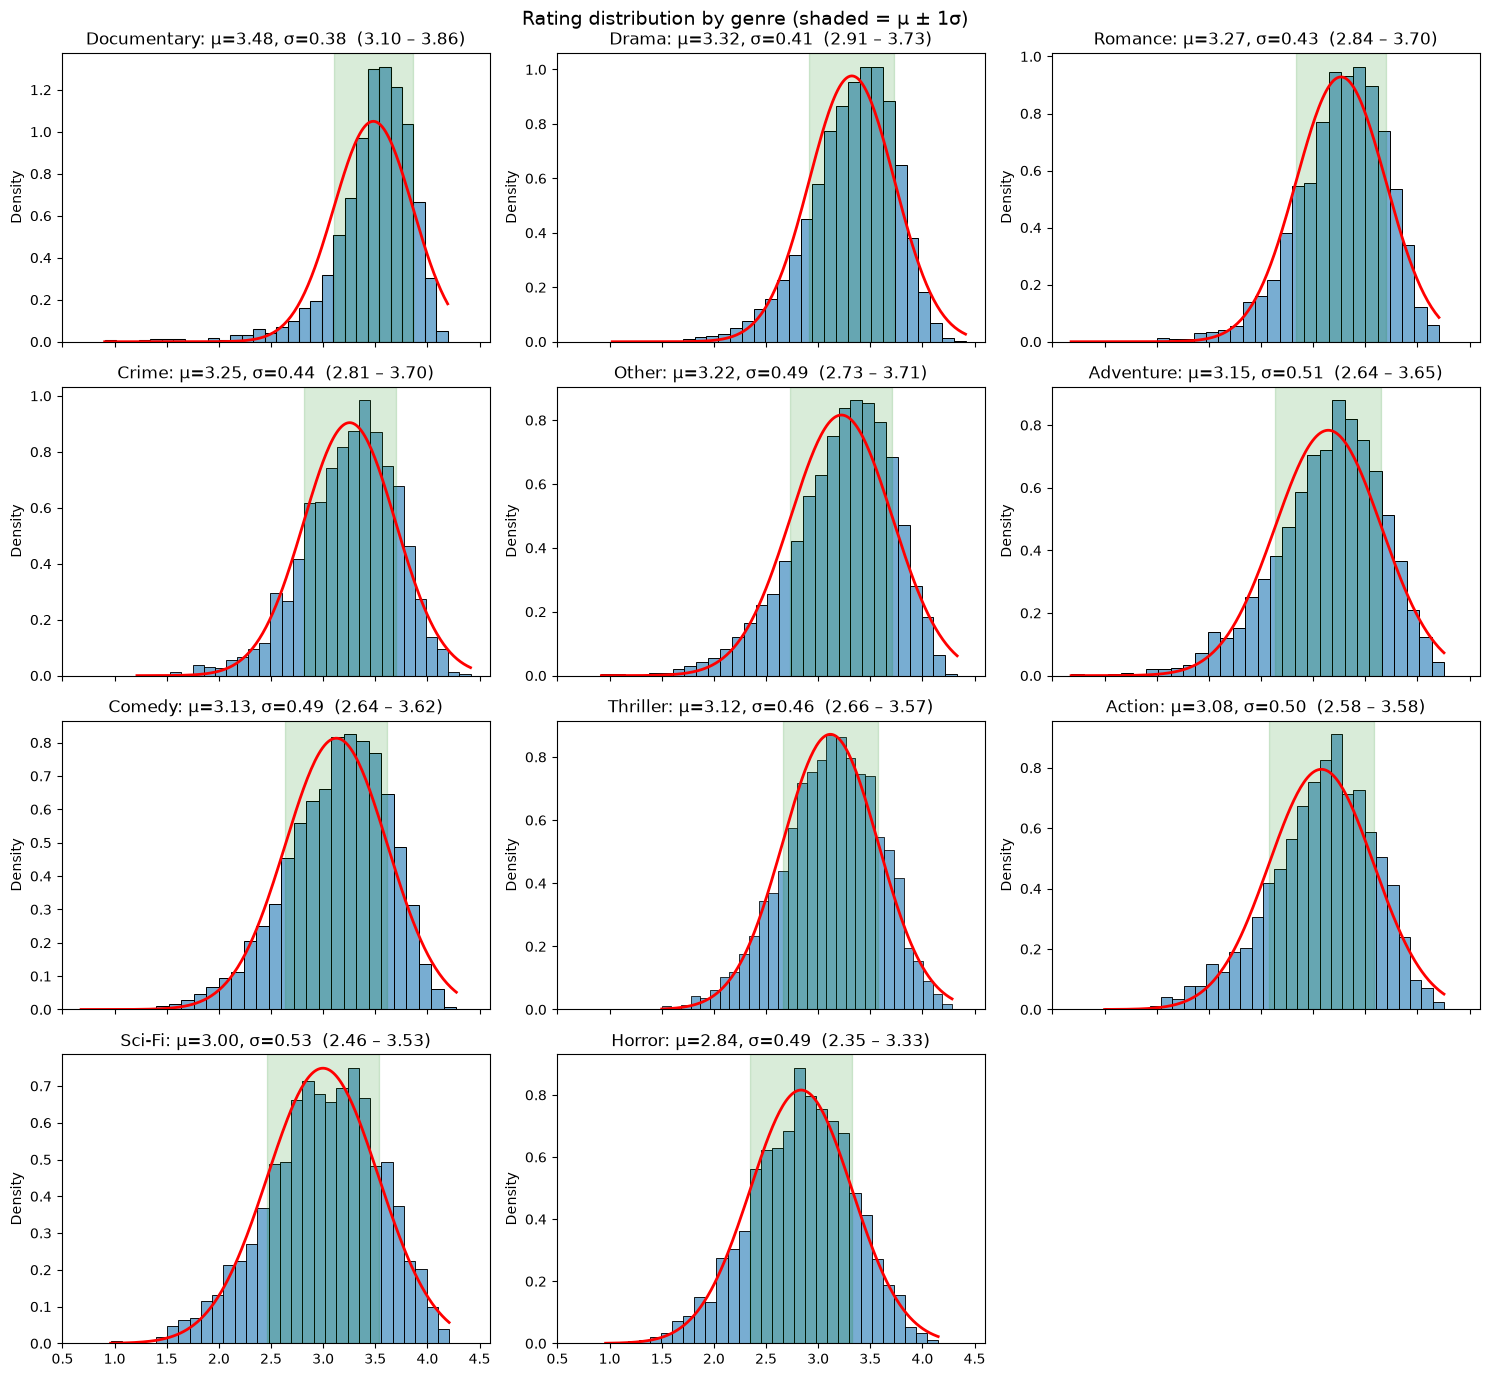

In [77]:
# μ, σ and the ±1σ range per genre
genre_stats = (
    genre_df.groupby("genre_group")["mean_rating"]
    .agg(n="count", mu="mean", sigma="std")
    .loc[order]
)
genre_stats["lower"] = genre_stats["mu"] - genre_stats["sigma"]
genre_stats["upper"] = genre_stats["mu"] + genre_stats["sigma"]

# Share of movies actually inside μ ± 1σ (would be 68% if perfectly normal)
tmp = genre_df.join(genre_stats[["lower", "upper"]], on="genre_group")
genre_stats["pct_within"] = (
    tmp["mean_rating"].between(tmp["lower"], tmp["upper"])
    .groupby(tmp["genre_group"]).mean() * 100
)

print(genre_stats.round(2))
genre_stats.to_csv(ARTIFACTS_DIR / "genre_rating_stats.csv")

# One histogram + normal curve per genre, shaded band = μ ± 1σ
fig, axes = plt.subplots(4, 3, figsize=(15, 14), sharex=True)
axes = axes.flatten()

for ax, (g, r) in zip(axes, genre_stats.iterrows()):
    data = genre_df.loc[genre_df["genre_group"] == g, "mean_rating"]
    sns.histplot(data, bins=30, stat="density", alpha=0.6, ax=ax)
    x = np.linspace(data.min(), data.max(), 200)
    sns.lineplot(x=x, y=stats.norm.pdf(x, r.mu, r.sigma), color="red", lw=2, ax=ax)
    ax.axvspan(r.lower, r.upper, color="green", alpha=0.15)
    ax.set_title(f"{g}: μ={r.mu:.2f}, σ={r.sigma:.2f}  ({r.lower:.2f} – {r.upper:.2f})")
    ax.set_xlabel("")

for ax in axes[len(genre_stats):]:   # hide the 12th empty slot
    ax.set_visible(False)

fig.suptitle("Rating distribution by genre (shaded = μ ± 1σ)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "genre_normal_fits.png", dpi=150, bbox_inches="tight")
plt.show()

**Result.** About 67–70% of movies fall inside μ ± 1σ in every genre except Documentary (76%), close to the 68% a normal curve gives. A per-genre μ ± σ range is a reasonable working approximation even though the overall distribution is skewed. μ ranges from 2.84 (Horror) to 3.48 (Documentary).

## 5. Rating test per genre
A movie passes the rating test if its average rating is between μ − 1σ and μ + 2σ of its genre (`LOWER_SD = 1`, `UPPER_SD = 2`).
- The upper bound is wider than the lower one on purpose. With μ + 1σ, many of the top-rated movies were rejected, which is not wanted.
- A movie with several genres gets its most forgiving range: the lowest lower bound and the highest upper bound among its genres.
- Movies with no listed genre fall into `Other`.
- The multipliers 1 and 2 were set by hand, not derived from the data (see the conclusion).

In [78]:
LOWER_SD = 1
UPPER_SD = 2      # set to None for no upper limit

# Test range per genre: (mu - LOWER_SD * sigma) to (mu + UPPER_SD * sigma)
bounds = genre_stats[["mu", "sigma"]].copy()
bounds["lower"] = bounds["mu"] - LOWER_SD * bounds["sigma"]
bounds["upper"] = bounds["mu"] + UPPER_SD * bounds["sigma"] if UPPER_SD else np.inf
print(bounds.round(2))

# Each movie's genre groups (top 10 genres, everything else -> Other; a movie with no genre also lands in Other)
movie_genres = (
    rated[["movieId", "genres"]]
    .assign(genre=rated["genres"].str.split("|"))
    .explode("genre")
    .loc[lambda d: ~d["genre"].isin(EXCLUDE)]
)
movie_genres["genre_group"] = movie_genres["genre"].where(
    movie_genres["genre"].isin(genre_stats.index), "Other"
)

# Per movie: lowest lower bound and highest upper bound among its genres
movie_bounds = (
    movie_genres.join(bounds[["lower", "upper"]], on="genre_group")
    .groupby("movieId")
    .agg(test_lower=("lower", "min"), test_upper=("upper", "max"))
)

rated = (rated.drop(columns=["test_lower", "test_upper", "pass_ratingtest"], errors="ignore")
              .join(movie_bounds, on="movieId"))

# 1 = pass, 0 = fail
rated["pass_ratingtest"] = (
    rated["mean_rating"].between(rated["test_lower"], rated["test_upper"]).astype(int)
)

print("\n", rated["pass_ratingtest"].value_counts())

too_high = rated[rated["mean_rating"] > rated["test_upper"]]
print(f"\n{len(too_high)} movies fail for being above the upper bound:")
print(too_high.nlargest(15, "mean_rating")[["title", "genres", "mean_rating", "rating_count"]])

               mu  sigma  lower  upper
genre_group                           
Documentary  3.48   0.38   3.10   4.24
Drama        3.32   0.41   2.91   4.14
Romance      3.27   0.43   2.84   4.13
Crime        3.25   0.44   2.81   4.14
Other        3.22   0.49   2.73   4.20
Adventure    3.15   0.51   2.64   4.16
Comedy       3.13   0.49   2.64   4.11
Thriller     3.12   0.46   2.66   4.03
Action       3.08   0.50   2.58   4.08
Sci-Fi       3.00   0.53   2.46   4.06
Horror       2.84   0.49   2.35   3.81

 pass_ratingtest
1    36456
0    13590
Name: count, dtype: int64

1678 movies fail for being above the upper bound:
                                                   title          genres  \
9243   Hijacking Catastrophe: 9/11, Fear & the Sellin...     Documentary   
9461                          Always a Bridesmaid (2000)     Documentary   
15202            Deadly Delicious (Shuang Shi Ji) (2008)   Drama|Mystery   
15842                  As Seen Through These Eyes (2008)     Documentary

**Result.** 36,456 movies pass the rating test and 13,590 fail. 1,678 fail because they are above the upper bound, and the highest of these are 5.0 averages from a single rating, which is why the count test is needed.

## 6. Rating counts by genre
Same question for popularity: do genres differ in how many ratings a movie gets? First attempt: fit a normal curve to log10(rating count) per genre and take μ − 1σ as the minimum count. Table saved to `artifacts/genre_count_stats.csv`, figure to `genre_count_fits.png`.

               mu  sigma  min_count  typical_count
genre_group                                       
Documentary  0.80   0.73          2              6
Drama        1.14   1.02          2             14
Romance      1.23   1.10          2             17
Crime        1.30   1.14          2             20
Other        1.28   1.13          2             19
Adventure    1.57   1.31          2             37
Comedy       1.22   1.10          2             17
Thriller     1.35   1.15          2             22
Action       1.36   1.23          2             23
Sci-Fi       1.54   1.26          2             35
Horror       1.18   0.99          2             15


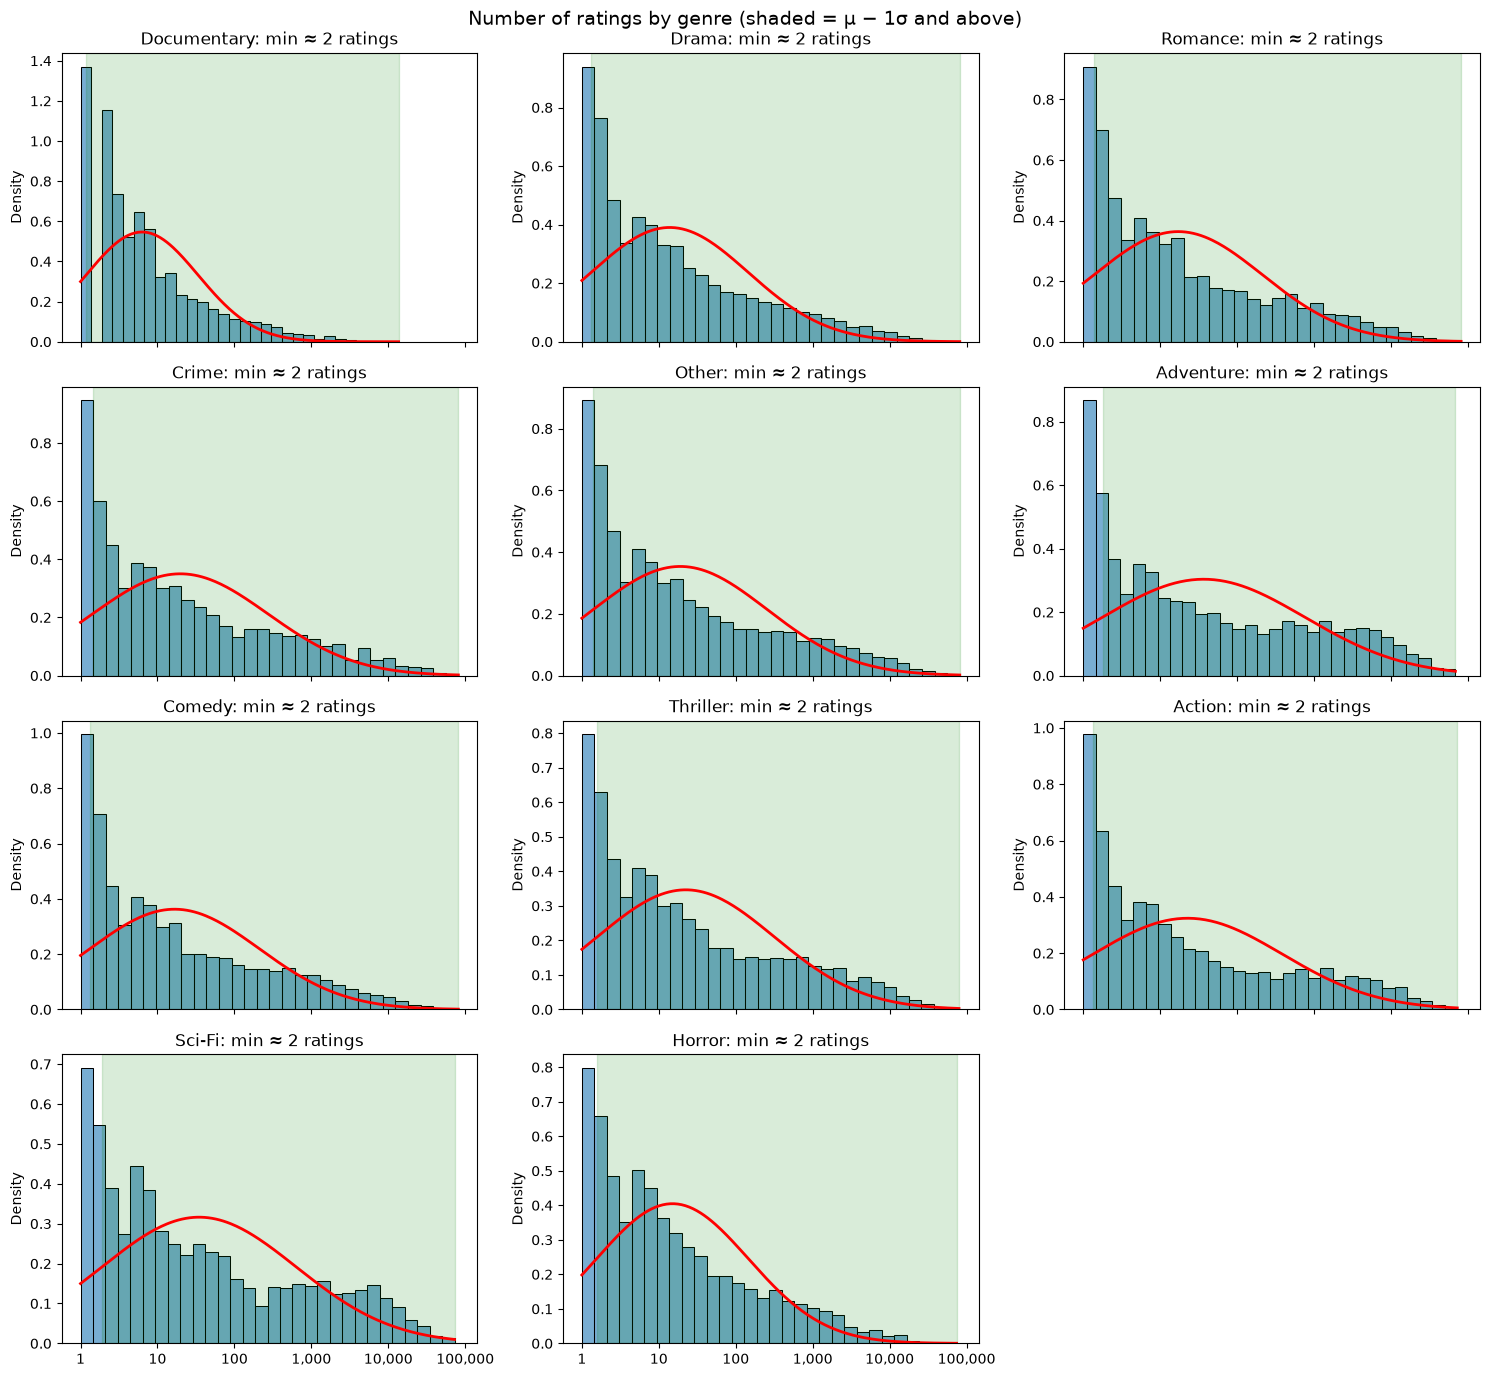

In [79]:
# One row per movie per genre group (all rated movies, no vote filter)
count_df = (
    movie_genres.drop_duplicates(["movieId", "genre_group"])
    .join(rated.set_index("movieId")["rating_count"], on="movieId")
)
count_df["log_count"] = np.log10(count_df["rating_count"].astype(float))

# μ, σ on log scale, then the lower end converted back to a rating count
count_stats = (
    count_df.groupby("genre_group")["log_count"]
    .agg(mu="mean", sigma="std")
    .loc[order]
)
count_stats["min_count"] = np.ceil(10 ** (count_stats["mu"] - count_stats["sigma"])).astype(int)
count_stats["typical_count"] = (10 ** count_stats["mu"]).round().astype(int)
print(count_stats.round(2))
count_stats.to_csv(ARTIFACTS_DIR / "genre_count_stats.csv")

# One histogram + normal curve per genre, shaded = passes (μ − 1σ and above)
fig, axes = plt.subplots(4, 3, figsize=(15, 14), sharex=True)
axes = axes.flatten()
ticks = range(0, int(np.ceil(count_df["log_count"].max())) + 1)

for ax, (g, r) in zip(axes, count_stats.iterrows()):
    data = count_df.loc[count_df["genre_group"] == g, "log_count"]
    sns.histplot(data, bins=30, stat="density", alpha=0.6, ax=ax)
    x = np.linspace(data.min(), data.max(), 200)
    sns.lineplot(x=x, y=stats.norm.pdf(x, r.mu, r.sigma), color="red", lw=2, ax=ax)
    ax.axvspan(r.mu - r.sigma, data.max(), color="green", alpha=0.15)
    ax.set_title(f"{g}: min ≈ {r.min_count:.0f} ratings")
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{10**t:,}" for t in ticks])
    ax.set_xlabel("")

for ax in axes[len(count_stats):]:   # hide the 12th empty slot
    ax.set_visible(False)

fig.suptitle("Number of ratings by genre (shaded = μ − 1σ and above)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "genre_count_fits.png", dpi=150, bbox_inches="tight")
plt.show()

**Result.** This does not work as a filter. The minimum comes out as 2 ratings for every genre, so it does not separate genres at all. The cell is kept for reference. The rest of the notebook uses quartiles instead.

Rating counts are extremely skewed (median 7, maximum 81,491 across all rated movies), so each genre is described with quartiles (Q1, median, Q3), which do not assume a shape. Saved to `artifacts/genre_count_summary.csv`, boxplot to `genre_count_boxplot.png`. The next cell shows the table as whole numbers.

              movies   q1  median     q3    iqr
genre_group                                    
Adventure     3541.0  3.0    16.0  430.0  427.0
Sci-Fi        2881.0  3.0    15.0  312.0  309.0
Thriller      7846.0  3.0    10.0  133.0  130.0
Crime         4976.0  2.0    10.0  105.0  103.0
Action        6440.0  2.0     9.0  153.0  151.0
Other        10887.0  2.0     9.0   95.0   93.0
Comedy       14947.0  2.0     8.0   84.0   82.0
Horror        5177.0  3.0     8.0   58.0   55.0
Romance       7179.0  2.0     8.0   80.0   78.0
Drama        24206.0  2.0     7.0   52.0   50.0
Documentary   4705.0  2.0     4.0   14.0   12.0


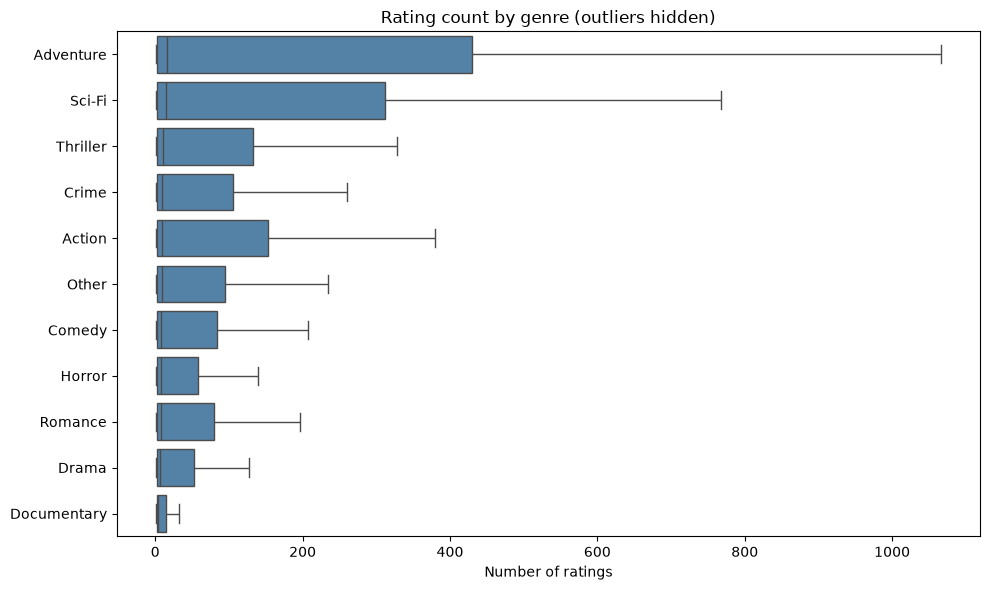

In [80]:
# One row per movie per genre group (all rated movies)
count_df = (
    rated[["movieId", "genres", "rating_count"]]
    .assign(genre=rated["genres"].str.split("|"))
    .explode("genre")
    .loc[lambda d: ~d["genre"].isin(EXCLUDE)]
)
count_df = count_df.assign(
    genre_group=count_df["genre"].where(count_df["genre"].isin(top_genres), "Other")
).drop_duplicates(["movieId", "genre_group"])

# Median, Q1, Q3 and IQR per genre
count_summary = (
    count_df.groupby("genre_group")["rating_count"]
    .describe()[["count", "25%", "50%", "75%"]]
    .rename(columns={"count": "movies", "25%": "q1", "50%": "median", "75%": "q3"})
)
count_summary["iqr"] = count_summary["q3"] - count_summary["q1"]
count_summary = count_summary.sort_values("median", ascending=False)
print(count_summary.round(0))
count_summary.to_csv(ARTIFACTS_DIR / "genre_count_summary.csv")

# Box plot, sorted by median count
plt.figure(figsize=(10, 6))
sns.boxplot(data=count_df, x="rating_count", y="genre_group",
            order=count_summary.index, color="steelblue", showfliers=False)
plt.xlabel("Number of ratings")
plt.ylabel("")
plt.title("Rating count by genre (outliers hidden)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "genre_count_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

In [81]:
count_summary.round(0).astype(int)

,movies,q1,median,q3,iqr
genre_group,,,,,
Adventure,3541,3,16,430,427
Sci-Fi,2881,3,15,312,309
Thriller,7846,3,10,133,130
Crime,4976,2,10,105,103
Action,6440,2,9,153,151
Other,10887,2,9,95,93
Comedy,14947,2,8,84,82
Horror,5177,3,8,58,55
Romance,7179,2,8,80,78


**Result.** Counts differ a lot by genre. The median is 16 ratings for Adventure and 15 for Sci-Fi but 4 for Documentary, and Adventure's Q3 is 430 against 14 for Documentary. One global minimum count would hit Documentary hardest, so the count test is per genre too.

Each movie gets the lowest Q1 and the lowest Q3 among its genres (the most forgiving values), then a level: `low` (fewer ratings than Q1), `high` (more than Q3), otherwise `mid`. The first cell below builds those two columns and the second assigns the levels. Result: 8,678 low, 29,237 mid, 12,131 high.

In [82]:
# Per movie: lowest q1 and lowest q3 among its genre groups (used by the count level below)
count_bounds = (
    count_df.join(count_summary[["q1", "q3"]], on="genre_group")
    .groupby("movieId")
    .agg(count_q1=("q1", "min"), count_q3=("q3", "min"))
)
rated = rated.drop(columns=["count_q1", "count_q3"], errors="ignore").join(count_bounds, on="movieId")

In [83]:
rated["count_level"] = np.select(
    [rated["rating_count"] < rated["count_q1"],
     rated["rating_count"] > rated["count_q3"]],
    ["low", "high"],
    default="mid",
)
rated.loc[rated["count_q3"].isna(), "count_level"] = np.nan   # stays NaN only if a movie has no genre group (none right now: no-genre movies are in Other)

# Ordered, so low < mid < high
rated["count_level"] = pd.Categorical(
    rated["count_level"], categories=["low", "mid", "high"], ordered=True
)

rated = rated.drop(columns=["count_zone", "pass_counttest"], errors="ignore")
print(rated["count_level"].value_counts(dropna=False, sort=False))

count_level
low      8678
mid     29237
high    12131
Name: count, dtype: int64


In [84]:
rated.head()

,movieId,tconst,tmdbId,title,genres,year,has_ratings,is_imdb_matched,rating_count,mean_rating,...,ml_genres,imdb_genres,ml_year,imdb_year,test_lower,test_upper,pass_ratingtest,count_q1,count_q3,count_level
0,1,tt0114709,862.0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,True,True,57309.0,3.893708,...,Adventure|Animation|Children|Comedy|Fantasy,"Adventure,Animation,Comedy",1995.0,1995.0,2.635945,4.201077,1,2.0,84.0,high
1,2,tt0113497,8844.0,Jumanji (1995),Adventure|Children|Fantasy,1995.0,True,True,24228.0,3.251527,...,Adventure|Children|Fantasy,"Adventure,Comedy,Family",1995.0,1995.0,2.635945,4.201077,1,2.0,95.0,high
2,3,tt0113228,15602.0,Grumpier Old Men (1995),Comedy|Romance,1995.0,True,True,11804.0,3.142028,...,Comedy|Romance,"Comedy,Romance",1995.0,1995.0,2.636070,4.126568,1,2.0,80.0,high
3,4,tt0114885,31357.0,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,True,True,2523.0,2.853547,...,Comedy|Drama|Romance,"Comedy,Drama,Romance",1995.0,1995.0,2.636070,4.140633,1,2.0,52.0,high
4,5,tt0113041,11862.0,Father of the Bride Part II (1995),Comedy,1995.0,True,True,11714.0,3.058434,...,Comedy,"Comedy,Family,Romance",1995.0,1995.0,2.636070,4.107801,1,2.0,84.0,high


Housekeeping: drop the helper columns (`count_q1`, `count_q3`), look at the table, rename the level to `count_level_test` so it is clear it belongs to the tests, and print the latest release year in the data (2026).

In [85]:
# helper columns, no longer needed once count_level is set
rated = rated.drop(columns=["count_min","count_q1","count_q3"], errors="ignore")

In [86]:
rated.head()

,movieId,tconst,tmdbId,title,genres,year,has_ratings,is_imdb_matched,rating_count,mean_rating,titleType,runtimeMinutes,ml_genres,imdb_genres,ml_year,imdb_year,test_lower,test_upper,pass_ratingtest,count_level
0,1,tt0114709,862.0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,True,True,57309.0,3.893708,movie,81,Adventure|Animation|Children|Comedy|Fantasy,"Adventure,Animation,Comedy",1995.0,1995.0,2.635945,4.201077,1,high
1,2,tt0113497,8844.0,Jumanji (1995),Adventure|Children|Fantasy,1995.0,True,True,24228.0,3.251527,movie,104,Adventure|Children|Fantasy,"Adventure,Comedy,Family",1995.0,1995.0,2.635945,4.201077,1,high
2,3,tt0113228,15602.0,Grumpier Old Men (1995),Comedy|Romance,1995.0,True,True,11804.0,3.142028,movie,101,Comedy|Romance,"Comedy,Romance",1995.0,1995.0,2.636070,4.126568,1,high
3,4,tt0114885,31357.0,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,True,True,2523.0,2.853547,movie,124,Comedy|Drama|Romance,"Comedy,Drama,Romance",1995.0,1995.0,2.636070,4.140633,1,high
4,5,tt0113041,11862.0,Father of the Bride Part II (1995),Comedy,1995.0,True,True,11714.0,3.058434,movie,106,Comedy,"Comedy,Family,Romance",1995.0,1995.0,2.636070,4.107801,1,high


In [87]:
rated = rated.rename(columns={"count_level": "count_level_test"})

In [88]:
print(int(rated["year"].max()))

2026


## 7. Age test: don't punish new movies
A recent movie has had little time to collect ratings, so a low count says nothing about its quality. The table and chart show the median rating count by movie age (age = `DATA_YEAR` − release year, with `DATA_YEAR` the latest year in the data). Figure saved to `rating_count_by_age.png`.

     movies  median  pct_of_peak
age                             
0         1     1.0          9.1
2         1     3.0         27.3
4         3     1.0          9.1
5         4     3.0         27.3
6         8     1.0          9.1
7       783     4.0         36.4
8      1796     4.0         36.4
9      2077     5.0         45.5
10     2149     5.0         45.5
11     2109     6.0         54.5
12     2082     6.0         54.5
13     1796     6.0         54.5
14     1686     5.5         50.0
15     1525     7.0         63.6
16     1422     6.5         59.1
17     1401     9.0         81.8
18     1334    10.0         90.9
19     1214    11.0        100.0
20     1166    10.0         90.9


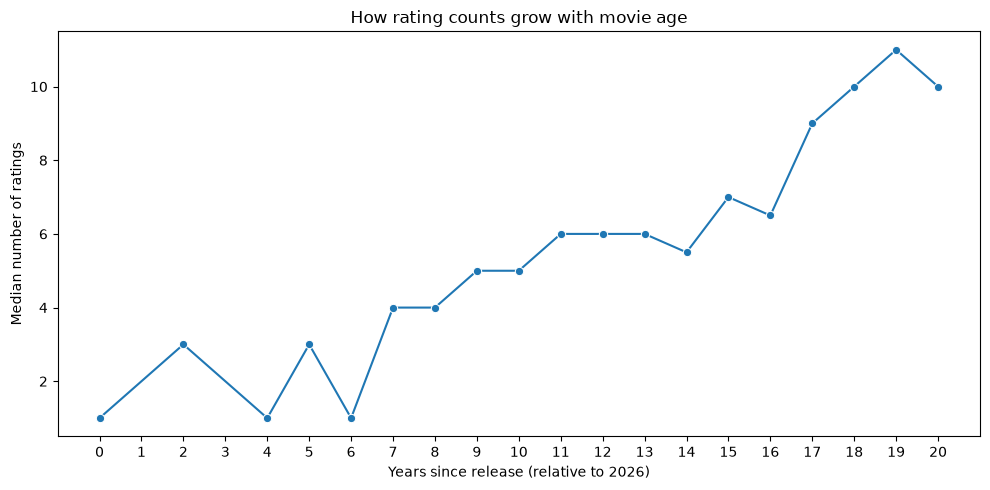

In [89]:
DATA_YEAR = int(rated["year"].max())   # latest release year in the data

age_df = rated.dropna(subset=["year"]).copy()
age_df["age"] = (DATA_YEAR - age_df["year"]).astype(int)

# Median rating count by movie age (first 20 years)
by_age = (age_df[age_df["age"] <= 20]
          .groupby("age")["rating_count"]
          .agg(movies="count", median="median"))
by_age["pct_of_peak"] = by_age["median"] / by_age["median"].max() * 100
print(by_age.round(1))

plt.figure(figsize=(10, 5))
sns.lineplot(x=by_age.index, y=by_age["median"], marker="o")
plt.xlabel(f"Years since release (relative to {DATA_YEAR})")
plt.ylabel("Median number of ratings")
plt.title("How rating counts grow with movie age")
plt.xticks(range(0, 21))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "rating_count_by_age.png", dpi=150, bbox_inches="tight")
plt.show()

**Result.** Counts keep growing with age: the median is 4 ratings for movies 7–8 years old and 11 for movies 19 years old. The youngest ages are nearly empty: only 17 movies are from 2020 or later, against 783 from 2019.

`MARGIN_YEARS = 8` marks movies released fewer than 8 years ago (2019 or later) as recent (`time_test = 0`). Older movies get `time_test = 1`.

In [90]:
MARGIN_YEARS = 8  # movies released fewer than this many years ago are "recent" (time_test = 0)
rated["time_test"] = ((DATA_YEAR - rated["year"]) >= MARGIN_YEARS).astype(int)
rated["time_test"].value_counts()

time_test
1    49244
0      802
Name: count, dtype: int64

The margin cannot be derived from this data. It exists to protect movies that have not had time to collect ratings, but almost no movies are newer than 2019, so the data cannot show how long "enough time" is. 8 was chosen by hand: it covers 2019, the only recent year with a real number of movies (783). 802 movies get `time_test = 0`; 2 of them have no year and are treated as old in the approve rule below. The next cell lists the movies from 2021 on, to see what the newest data looks like.

In [91]:
rated.loc[rated["year"] >= 2021, ["title", "year", "imdb_year", "rating_count"]]

,title,year,imdb_year,rating_count
19062,Sol (2012),2021.0,2021.0,1.0
36917,The Prey (2014),2022.0,2022.0,1.0
44226,The Death of April (2012),2022.0,2022.0,2.0
45525,Scott and Sid,2021.0,2021.0,3.0
48992,Das Fest des Huhnes (1992),2026.0,2026.0,1.0
49510,Chaos Walking (2019),2021.0,2021.0,7.0
49801,Wicked,2024.0,2024.0,3.0
49802,Uncharted: Drake's Fortune,2022.0,2022.0,1.0
49995,Deadly Switch (2019),2021.0,2021.0,3.0


In [92]:
rated.head()

,movieId,tconst,tmdbId,title,genres,year,has_ratings,is_imdb_matched,rating_count,mean_rating,...,runtimeMinutes,ml_genres,imdb_genres,ml_year,imdb_year,test_lower,test_upper,pass_ratingtest,count_level_test,time_test
0,1,tt0114709,862.0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,True,True,57309.0,3.893708,...,81,Adventure|Animation|Children|Comedy|Fantasy,"Adventure,Animation,Comedy",1995.0,1995.0,2.635945,4.201077,1,high,1
1,2,tt0113497,8844.0,Jumanji (1995),Adventure|Children|Fantasy,1995.0,True,True,24228.0,3.251527,...,104,Adventure|Children|Fantasy,"Adventure,Comedy,Family",1995.0,1995.0,2.635945,4.201077,1,high,1
2,3,tt0113228,15602.0,Grumpier Old Men (1995),Comedy|Romance,1995.0,True,True,11804.0,3.142028,...,101,Comedy|Romance,"Comedy,Romance",1995.0,1995.0,2.636070,4.126568,1,high,1
3,4,tt0114885,31357.0,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,True,True,2523.0,2.853547,...,124,Comedy|Drama|Romance,"Comedy,Drama,Romance",1995.0,1995.0,2.636070,4.140633,1,high,1
4,5,tt0113041,11862.0,Father of the Bride Part II (1995),Comedy,1995.0,True,True,11714.0,3.058434,...,106,Comedy,"Comedy,Family,Romance",1995.0,1995.0,2.636070,4.107801,1,high,1


## 8. Combine the tests into `approve`
First the rating side: `too_low`, `normal` or `too_high` against the genre's range. Then the rules, in order of priority:
- **Recent** movies (2019 or later) are approved, whatever their counts or ratings.
- **High** count: approved, even with a low rating. Many ratings is a real signal.
- **Mid** count: approved if the rating is normal. If it is too high, approved only when the count is at least the genre's median. If it is too low, rejected.
- **Low** count: rejected.

The crosstab shows every combination so the rules can be checked, and the last table lists the highest-rated rejected movies.

In [93]:
# Split the rating test into too_low / normal / too_high
rated["rating_side"] = np.select(
    [rated["mean_rating"] < rated["test_lower"],
     rated["mean_rating"] > rated["test_upper"]],
    ["too_low", "too_high"],
    default="normal",
)

# Per movie: lowest genre median count among its genres (for the mid + too_high rule)
movie_median = (
    count_df.join(count_summary["median"], on="genre_group")
    .groupby("movieId")["median"].min()
    .rename("count_median")
)
rated = rated.drop(columns=["count_median"], errors="ignore").join(movie_median, on="movieId")

level = rated["count_level_test"]
side = rated["rating_side"]
recent = rated["year"].notna() & (rated["time_test"] == 0)   # missing year = treated as old
has_genre = rated["test_lower"].notna() & level.notna()   # safety check: every movie should have bounds and a count level

approve = (
    recent
    | (has_genre & (level == "high"))
    | (has_genre & (level == "mid") & (side == "normal"))
    | (has_genre & (level == "mid") & (side == "too_high")
       & (rated["rating_count"] >= rated["count_median"]))
)
rated["approve"] = approve.astype(int)

print(rated["approve"].value_counts())

# Check every combination: approve counts per count level and rating side
print(pd.crosstab([rated["count_level_test"], rated["rating_side"]], rated["approve"]))

# Safety check: highest-rated movies that got rejected
print(rated[rated["approve"] == 0]
      .nlargest(15, "mean_rating")[["title", "mean_rating", "rating_count",
                                    "count_level_test", "rating_side"]])

approve
1    33812
0    16234
Name: count, dtype: int64
approve                          0      1
count_level_test rating_side             
low              normal       4203     90
                 too_high      988     22
                 too_low      3289     86
mid              normal          0  21146
                 too_high      591     38
                 too_low      7163    299
high             normal          0  11017
                 too_high        0     39
                 too_low         0   1075
                                                   title  mean_rating  \
9243   Hijacking Catastrophe: 9/11, Fear & the Sellin...          5.0   
9461                          Always a Bridesmaid (2000)          5.0   
15202            Deadly Delicious (Shuang Shi Ji) (2008)          5.0   
15842                  As Seen Through These Eyes (2008)          5.0   
17273         Eye for an Eye, An (Silmä silmästä) (1999)          5.0   
17485        Joffrey: Mavericks of American 

In [94]:
rated.head()

,movieId,tconst,tmdbId,title,genres,year,has_ratings,is_imdb_matched,rating_count,mean_rating,...,ml_year,imdb_year,test_lower,test_upper,pass_ratingtest,count_level_test,time_test,rating_side,count_median,approve
0,1,tt0114709,862.0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,True,True,57309.0,3.893708,...,1995.0,1995.0,2.635945,4.201077,1,high,1,normal,8.0,1
1,2,tt0113497,8844.0,Jumanji (1995),Adventure|Children|Fantasy,1995.0,True,True,24228.0,3.251527,...,1995.0,1995.0,2.635945,4.201077,1,high,1,normal,9.0,1
2,3,tt0113228,15602.0,Grumpier Old Men (1995),Comedy|Romance,1995.0,True,True,11804.0,3.142028,...,1995.0,1995.0,2.636070,4.126568,1,high,1,normal,8.0,1
3,4,tt0114885,31357.0,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,True,True,2523.0,2.853547,...,1995.0,1995.0,2.636070,4.140633,1,high,1,normal,7.0,1
4,5,tt0113041,11862.0,Father of the Bride Part II (1995),Comedy,1995.0,True,True,11714.0,3.058434,...,1995.0,1995.0,2.636070,4.107801,1,high,1,normal,8.0,1


**Result.** 33,812 movies approved (67.6%) and 16,234 rejected. Of the rejected, 8,480 have a low count and 7,754 have a mid count with a rating outside the range. All 12,131 high-count movies are approved, and the only low-count movies approved are the 198 recent ones.

### Sanity checks
Movies with a perfect 5.0 average, by rating count. The checks below should show that rejected movies are noise or genuinely low-rated, not hidden gems.

In [95]:
rated.loc[rated["mean_rating"] == 5, "rating_count"].value_counts().sort_index()

rating_count
1.0    688
2.0     22
3.0      3
Name: count, dtype: int64

**Result.** All 713 movies with a 5.0 average have 3 or fewer ratings (688 have just one). A perfect average from one rating is noise, so rejecting them is expected.

The 15 most-rated movies that were rejected.

In [96]:
rated[rated["approve"] == 0].nlargest(15, "rating_count")[
    ["title", "genres", "mean_rating", "rating_count", "count_level_test", "rating_side"]
]

,title,genres,mean_rating,rating_count,count_level_test,rating_side
2347,Firewalker (1986),Adventure,2.437063,286.0,mid,too_low
2407,Beyond the Poseidon Adventure (1979),Adventure,1.977612,268.0,mid,too_low
5674,"Tarzan, the Ape Man (1981)",Adventure,2.028481,158.0,mid,too_low
20306,"Legend of Hercules, The (2014)",Action|Adventure,2.372549,153.0,mid,too_low
5396,Aspen Extreme (1993),Action,2.549669,151.0,mid,too_low
1123,Best of the Best 3: No Turning Back (1995),Action,2.013423,149.0,mid,too_low
5029,"Octagon, The (1980)",Action,2.329932,147.0,mid,too_low
47446,Robin Hood (2018),Adventure,2.578231,147.0,mid,too_low
7105,Fire Birds (1990),Action|Adventure,2.388889,135.0,mid,too_low
4395,Best of the Best 2 (1993),Action,2.458647,133.0,mid,too_low


**Result.** All 15 have a mid count and a too-low rating (about 2.0 to 2.6) with 113–286 ratings, so they are genuinely low-rated rather than hidden gems.

## 9. Approved movies: check and clean
Keep the approved movies (33,812 rows, 24 columns), then check missing values and column types.

In [97]:
approved_movies = rated[rated["approve"] == 1].copy()
print(f"{len(approved_movies):,} approved movies, {approved_movies.shape[1]} columns")

33,812 approved movies, 24 columns


In [98]:
summary = pd.DataFrame({
    "dtype": approved_movies.dtypes,
    "missing": approved_movies.isna().sum(),
    "missing_%": (approved_movies.isna().mean() * 100).round(1),
})
print(summary)

                     dtype  missing  missing_%
movieId              int64        0        0.0
tconst                 str        0        0.0
tmdbId             float64       30        0.1
title                  str        0        0.0
genres                 str       10        0.0
year               float64        0        0.0
has_ratings           bool        0        0.0
is_imdb_matched       bool        0        0.0
rating_count       float64        0        0.0
mean_rating        float64        0        0.0
titleType              str       90        0.3
runtimeMinutes         str       95        0.3
ml_genres              str     1318        3.9
imdb_genres            str       98        0.3
ml_year            float64      114        0.3
imdb_year          float64       90        0.3
test_lower         float64        0        0.0
test_upper         float64        0        0.0
pass_ratingtest      int64        0        0.0
count_level_test  category        0        0.0
time_test    

Two more checks: no comma-style genres should be left (must print 0), and which title types are present (`movie`, or missing for the 90 rows IMDb could not match).

In [99]:
# 1. Any IMDb-style comma genres left? (should print 0), then movies whose genres came from IMDb
print(approved_movies["genres"].str.contains(",", na=False).sum())
print(approved_movies.loc[approved_movies["ml_genres"].isna(), ["title", "genres", "imdb_genres"]].head())

# 2. Which title types are present?
print(approved_movies["titleType"].value_counts(dropna=False))

0
                                              title                 genres  \
15870                       Trails (Veredas) (1978)          Drama|Fantasy   
16734                      Milky Way (Tejút) (2007)                  Drama   
17019  Dancing Hawk, The (Tanczacy jastrzab) (1978)                  Drama   
17046       Warsaw Bridge (Pont de Varsòvia) (1990)                  Drama   
17676                   Les hautes solitudes (1974)  Biography|Documentary   

                 imdb_genres  
15870          Drama,Fantasy  
16734                  Drama  
17019                  Drama  
17046                  Drama  
17676  Biography,Documentary  
titleType
movie    33722
NaN         90
Name: count, dtype: int64


Fix types: year, counts and IDs are whole numbers stored as floats (use nullable `Int64` so missing values are kept), and runtime is text, so convert it to a number.

In [100]:
# Whole-number columns stored as floats
for c in ["year", "rating_count", "tmdbId", "ml_year", "imdb_year"]:
    approved_movies[c] = approved_movies[c].astype("Int64")

# Runtime: text -> number (non-numeric values such as IMDb's "\N" become missing)
approved_movies["runtimeMinutes"] = pd.to_numeric(approved_movies["runtimeMinutes"], errors="coerce").astype("Int64")

### Clean up the columns
Drop what is no longer needed now that filtering is done:
- the test columns: `test_lower`, `test_upper`, `pass_ratingtest`, `count_level_test`, `time_test`, `rating_side`, `count_median`
- `ml_year` and `imdb_year`: `year` is complete and already follows IMDb, falling back to MovieLens (it equals `imdb_year` on all 33,722 IMDb-matched rows and `ml_year` on the other 90)
- `ml_genres` and `imdb_genres`: `genres` already combines them
- `is_imdb_matched`, `titleType`, `approve`, `has_ratings`: constant, or only flagging the 90 unmatched rows
- 10 movies with no genre: they cannot be grouped, and IMDb has no genre for them either.

In [101]:
# Filtering is done: drop the intermediate test columns
test_cols = ["test_lower", "test_upper", "pass_ratingtest", "count_level_test",
             "time_test", "rating_side", "count_median"]

# year is complete and already follows IMDb, falling back to MovieLens, so the source years are redundant
assert approved_movies["year"].notna().all()
year_cols = ["ml_year", "imdb_year"]

# genres is already merged from ml_genres + imdb_genres; titleType is "movie" or missing; approve and has_ratings are constant
other_cols = ["is_imdb_matched", "ml_genres", "imdb_genres", "titleType", "approve", "has_ratings"]

approved_movies = approved_movies.drop(columns=test_cols + year_cols + other_cols)

# Missing genre can't be grouped, and IMDb has none either (genres was backfilled from it)
n_before = len(approved_movies)
approved_movies = approved_movies.dropna(subset=["genres"]).reset_index(drop=True)
print(f"dropped {n_before - len(approved_movies)} rows with no genre")
print(f"{approved_movies.shape[0]:,} rows, {approved_movies.shape[1]} columns: {approved_movies.columns.tolist()}")

dropped 10 rows with no genre
33,802 rows, 9 columns: ['movieId', 'tconst', 'tmdbId', 'title', 'genres', 'year', 'rating_count', 'mean_rating', 'runtimeMinutes']


### Save
Write the cleaned table and a small metadata file (source, parameters, row count, columns) to `data/processed/`. If the file already exists the cell does nothing, so nothing is overwritten.

In [102]:
# Save the cleaned approved set (skipped if it already exists)
import json
from datetime import datetime, timezone

APPROVED_MOVIES_PATH = PROCESSED_DIR / "approved_movies.parquet"
META_PATH = PROCESSED_DIR / "approved_movies.metadata.json"

if APPROVED_MOVIES_PATH.exists():
    print(f"{APPROVED_MOVIES_PATH} already exists, not overwriting.")
else:
    approved_movies.to_parquet(APPROVED_MOVIES_PATH, index=False)
    meta = {
        "created_at": datetime.now(timezone.utc).isoformat(),
        "source": "data/processed/movies_full.parquet",
        "produced_by": "notebooks/04_eda.ipynb",
        "row_count": len(approved_movies),
        "columns": approved_movies.columns.tolist(),
        "parameters": {
            "MIN_VOTES": MIN_VOTES, "MIN_MOVIES": MIN_MOVIES, "TOP_N": TOP_N,
            "EXCLUDE": sorted(EXCLUDE), "LOWER_SD": LOWER_SD, "UPPER_SD": UPPER_SD,
            "MARGIN_YEARS": MARGIN_YEARS, "DATA_YEAR": DATA_YEAR,
        },
        "metrics": {
            "rated_movies": len(rated),
            "approved_before_cleanup": int(rated["approve"].sum()),
        },
    }
    META_PATH.write_text(json.dumps(meta, indent=2))
    print(f"saved {len(approved_movies):,} rows to {APPROVED_MOVIES_PATH}")

../data/processed/approved_movies.parquet already exists, not overwriting.


## Conclusion
- **Ratings are not normal.** They are left-skewed (skewness −0.70), so normal-based bounds are approximations.
- **Genre matters for ratings.** Genre medians run from 2.86 (Horror) to 3.54 (Documentary). One global rating cutoff would unfairly hit the lower-rated genres, so the rating test is per genre.
- **Genre matters for rating counts too.** Median counts run from 4 (Documentary) to 16 (Adventure), so the count test is per genre as well.
- **Result.** 33,812 of 50,046 rated movies are approved (67.6%). After removing 10 movies with no genre, 33,802 rows and 9 columns are saved to `data/processed/approved_movies.parquet`.

**Still to decide before Step 4 is final.** These values were chosen by hand, not derived from the data, and are not yet checked against held-out ratings:
- `LOWER_SD = 1` and `UPPER_SD = 2`
- `MIN_VOTES = 10` for the distribution checks
- `MARGIN_YEARS = 8`
- using the 10 largest genres and grouping the rest as `Other`

The tests also remove 32.4% of rated movies. The project goal is not to exclude a major portion of the catalog, so this needs a sensitivity check.